# 04 — FastFit / BANKING77 Full Pool

使用清理后的全部 8,996 条训练样本，默认只评估 1,000 条 Validation。`SHOT_BUDGET=None` 表示 Full Pool，`SEED=42`。`FINAL_TEST=True` 仅用于配置冻结后的最终评估，使用同一个已训练模型。

选择 **Python (FastFit CW1)** 内核。当前兼容组合为 `fast-fit==1.2.1`、`transformers==4.44.2`、`datasets==2.21.0`、`accelerate==0.34.2` 和 `huggingface-hub<1`。缺少依赖时，setup 会列出对应内核的安装命令。数据和预训练模型可使用 Hugging Face 缓存。

训练、指标和错误分析在 Notebook 内完成。运行后保存 `.ipynb`，以保留表格、图和真实执行输出。

参考 [IBM FastFit](https://github.com/IBM/fastfit) 与 [Yehudai 和 Bandel，NAACL 2024](https://aclanthology.org/2024.naacl-demo.18/)。

In [1]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
from importlib import util, metadata
import platform, subprocess, sys
from tempfile import TemporaryDirectory
required = {"numpy":"numpy", "pandas":"pandas", "torch":"torch", "datasets":"datasets", "transformers":"transformers", "fastfit":"fast-fit", "sklearn":"scikit-learn", "accelerate":"accelerate", "matplotlib":"matplotlib", "huggingface_hub":"huggingface-hub"}
compatible = {"fast-fit": "1.2.1", "datasets": "2.21.0", "transformers": "4.44.2", "accelerate": "0.34.2"}
install_specs = {p: f"{p}=={v}" for p, v in compatible.items()}
install_specs["huggingface-hub"] = "huggingface-hub<1"
missing = [package for module, package in required.items() if util.find_spec(module) is None]
if missing:
    command = [sys.executable, "-m", "pip", "install", *[install_specs.get(p, p) for p in missing]]
    raise RuntimeError(f"FastFit kernel is missing {missing}. Install in the dedicated kernel: {subprocess.list2cmdline(command)}")
VERSIONS = {p: metadata.version(p) for p in required.values()}
VERSIONS["python"] = platform.python_version()
print("Interpreter:", sys.executable)
print("Versions:", VERSIONS)
conflicts = {p: (VERSIONS[p], v) for p, v in compatible.items() if VERSIONS[p] != v}
if int(VERSIONS["huggingface-hub"].split(".")[0]) >= 1:
    conflicts["huggingface-hub"] = (VERSIONS["huggingface-hub"], "<1")
if conflicts:
    command = [sys.executable, "-m", "pip", "install", *[install_specs[p] for p in conflicts]]
    raise RuntimeError(f"Installed vs required versions: {conflicts}. Select Python (FastFit CW1), or repair only a dedicated environment: {subprocess.list2cmdline(command)}")

import hashlib, inspect, json, random, re, time
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix
from IPython.display import display
import matplotlib.pyplot as plt

DATASET = "banking77"
METHOD = "fastfit"
EXPECTED_CLASSES = 77
EXPECTED_SIZES = (8996, 1000, 3080)
SEED = 42
SHOT_BUDGET = None
SAMPLING_MODE = "independent"
FINAL_TEST = False
RUN_SHOT_GRID = False
RUN_MULTI_SEED = False
if RUN_SHOT_GRID or RUN_MULTI_SEED:
    raise ValueError("This notebook runs one main condition. Keep grid and multiseed switches False.")
BACKBONE = "roberta-base"
NUM_EPOCHS = 1
BATCH_SIZE = 16
NUM_REPEATS = 4
CLF_LOSS_FACTOR = 0.1
OPTIM = "adafactor"
MAX_TEXT_LENGTH = 128
VALIDATION_FRACTION = 0.10
cwd = Path.cwd()
PROJECT = cwd.parent if cwd.name == "notebooks" else cwd
CLINC_SHA256 = "36923c3705a59e08fe9c3883d8bc2dd966ef93e22cb78ac41171782a698d56e0"
NORMALIZATION = "strip/collapse whitespace and Unicode casefold; punctuation retained"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU"
print("Device:", DEVICE, "| GPU:", GPU_NAME, "| CUDA available:", torch.cuda.is_available())
def normalize_text(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Text must be a non-empty string")
    return re.sub(r'\s+', ' ', text).strip().casefold()

def text_hash(text):
    return hashlib.sha256(normalize_text(text).encode("utf-8")).hexdigest()

def audit_overlap(left, right, left_name, right_name):
    a = left.assign(_key=left["text"].map(normalize_text))
    b = right.assign(_key=right["text"].map(normalize_text))
    # Keep the original audit column order for the saved 01 evidence.
    pairs = a.drop(columns="text_sha256", errors="ignore").merge(
        b.drop(columns="text_sha256", errors="ignore"),
        on="_key", suffixes=("_left", "_right")
    )
    report = {
        "left": left_name, "right": right_name,
        "matching_pairs": len(pairs), "unique_texts": int(pairs["_key"].nunique()),
        "left_rows": int(pairs["source_id_left"].nunique()),
        "right_rows": int(pairs["source_id_right"].nunique()),
        "conflicting_pairs": int((pairs["label_left"] != pairs["label_right"]).sum()),
    }
    return report, pairs

def remove_train_overlap(train, protected, name):
    report, pairs = audit_overlap(train, protected, name, "protected")
    drop_ids = set(pairs["source_id_left"])
    cleaned = train.loc[~train["source_id"].isin(drop_ids)].copy()
    assert len(train) - len(cleaned) == report["left_rows"]
    print(name, "removed training rows:", len(drop_ids),
          "conflicting pairs:", report["conflicting_pairs"])
    return cleaned, report, pairs

def verify_disjoint(a, b, name_a, name_b):
    overlap = set(a["text_sha256"]) & set(b["text_sha256"])
    assert not overlap, f"Normalized-text overlap: {name_a} / {name_b}"
    assert set(a["source_id"]).isdisjoint(b["source_id"])
    return {"left": name_a, "right": name_b, "unique_texts": len(overlap)}

def make_source_ids(df, dataset_name, split_name):
    prefix = "banking77" if dataset_name == "banking77" else "clinc"
    result = df.copy()
    result["source_id"] = [f"{prefix}_{split_name}_{i}" for i in range(len(result))]
    result["text_sha256"] = result["text"].map(text_hash)
    return result

def read_original_clinc():
    """Read optional local original data, or download in memory; never export JSON."""
    path = PROJECT / "data" / "clinc150" / "data_full.json"
    if path.exists():
        content = path.read_bytes()
    else:
        import urllib.request
        url = "https://raw.githubusercontent.com/clinc/oos-eval/master/data/data_full.json"
        content = urllib.request.urlopen(url, timeout=90).read()
    assert hashlib.sha256(content).hexdigest() == CLINC_SHA256, "Original CLINC SHA256 mismatch"
    return json.loads(content)

def sample_fewshot(pool, shot_budget, seed, sampling_mode):
    """Sample a few-shot set; nested budgets share per-class random prefixes."""
    if sampling_mode not in {"independent", "nested"}:
        raise ValueError("sampling_mode must be 'independent' or 'nested'")
    if shot_budget is None:
        return pool.copy()
    if type(shot_budget) is not int or shot_budget <= 0:
        raise ValueError("shot_budget must be None or a positive integer")
    if sampling_mode == "nested" and shot_budget > 16:
        raise ValueError("nested sampling supports shot budgets up to 16")
    assert pool.groupby("label").size().min() >= shot_budget, "Insufficient examples per class"
    if sampling_mode == "independent":
        # Preserve legacy pandas sample behavior, IDs and row order exactly.
        return pool.groupby("label", group_keys=False).sample(
            n=shot_budget, random_state=seed).copy()

    rng = np.random.RandomState(seed)
    chosen_ids = []
    for label in sorted(pool["label"].unique().tolist()):
        class_ids = pool.loc[pool["label"] == label, "source_id"].to_numpy()
        chosen_ids.extend(rng.permutation(class_ids)[:shot_budget].tolist())
    selected_ids = set(chosen_ids)
    return pool.loc[pool["source_id"].isin(selected_ids)].copy()

def build_protocol(dataset_name, shot_budget=8, seed=42, validation_fraction=0.10,
                   sampling_mode="independent"):
    if dataset_name not in {"banking77", "clinc150"}:
        raise ValueError("Choose banking77 or clinc150")
    if shot_budget is not None and (type(shot_budget) is not int or shot_budget <= 0):
        raise ValueError("shot_budget must be None or a positive integer")
    if sampling_mode not in {"independent", "nested"}:
        raise ValueError("sampling_mode must be 'independent' or 'nested'")
    if sampling_mode == "nested" and shot_budget is not None and shot_budget > 16:
        raise ValueError("nested sampling supports shot budgets up to 16")
    if type(seed) is not int or not 0 <= seed < 2**32:
        raise ValueError("seed must be an integer in [0, 2**32)")
    if not 0 < validation_fraction < 1:
        raise ValueError("validation_fraction must be between zero and one")
    audits = {}
    pairs = {}
    oos_audit = []
    original_sha256 = None
    if dataset_name == "banking77":
        raw = load_dataset("PolyAI/banking77")
        id_to_name = dict(enumerate(raw["train"].features["label"].names))
        expected_classes = 77
        train = make_source_ids(raw["train"].to_pandas(), dataset_name, "train")
        test = make_source_ids(raw["test"].to_pandas(), dataset_name, "test")
        cleaned, audits["train_vs_test"], pairs["train_vs_test"] = remove_train_overlap(train, test, "banking_train")
        pool, validation = train_test_split(
            cleaned, test_size=validation_fraction, random_state=seed,
            stratify=cleaned["label"]
        )
        pool, audits["pool_vs_validation"], pairs["pool_vs_validation"] = remove_train_overlap(pool, validation, "banking_pool")
        original_splits = {"train": train, "test": test}
        expected_labels = set(id_to_name)
    else:
        original = read_original_clinc()
        original_sha256 = CLINC_SHA256
        converted = load_dataset("DeepPavlov/clinc150", "default")
        id_to_names = defaultdict(set)
        original_splits = {}
        all_original_texts = {text for rows in original.values() for text, label in rows}
        for split, raw_name in [("train", "train"), ("validation", "val"), ("test", "test")]:
            raw_rows = original[raw_name]
            text_to_names = defaultdict(set)
            for text, name in raw_rows:
                text_to_names[text].add(name)
            assert all(len(names) == 1 for names in text_to_names.values()), "Ambiguous original labels"
            hf_frame = converted[split].to_pandas()
            known = hf_frame.loc[hf_frame["label"].notna()]
            assert Counter(known["utterance"]) == Counter(text for text, name in raw_rows)
            for text, number in zip(known["utterance"], known["label"]):
                id_to_names[int(number)].update(text_to_names[text])
            missing = Counter(hf_frame.loc[hf_frame["label"].isna(), "utterance"])
            oos = Counter(text for text, name in original["oos_" + raw_name])
            unknown = missing - oos
            assert not (oos - missing), "Original OOS rows missing from converted split"
            oos_audit.append({
                "split": split, "null_labels": sum(missing.values()),
                "original_oos_matches": sum((missing & oos).values()),
                "unconfirmed_extra_rows": sum(unknown.values()),
                "extra_rows_in_any_original_split": sum(n for text, n in unknown.items() if text in all_original_texts),
            })
            frame = pd.DataFrame(raw_rows, columns=["text", "label"])
            # Preserve the established IDs: i indexes original JSON in-domain rows.
            original_splits[split] = make_source_ids(frame, dataset_name, split)
        assert len(id_to_names) == 150 and all(len(names) == 1 for names in id_to_names.values())
        id_to_name = {number: next(iter(names)) for number, names in id_to_names.items()}
        assert set(id_to_name) == set(range(150)) and len(set(id_to_name.values())) == 150
        expected_classes = 150
        expected_labels = set(id_to_name.values())
        train = original_splits["train"]
        validation = original_splits["validation"]
        test = original_splits["test"]
        pool, audits["train_vs_validation"], pairs["train_vs_validation"] = remove_train_overlap(train, validation, "clinc_train")
        pool, audits["train_vs_test_after_validation"], pairs["train_vs_test_after_validation"] = remove_train_overlap(pool, test, "clinc_train")

    checks = []
    for a, b, an, bn in [
        (pool, validation, "pool", "validation"),
        (pool, test, "pool", "test"),
        (validation, test, "validation", "test"),
    ]:
        checks.append(verify_disjoint(a, b, an, bn))
    for frame, frame_name in [(pool, "pool"), (validation, "validation"), (test, "test")]:
        assert set(frame["label"]) == expected_labels, f"Unexpected labels in {frame_name}"
        assert frame["source_id"].is_unique, f"Duplicate source_id in {frame_name}"
        assert frame["text_sha256"].equals(frame["text"].map(text_hash)), f"Hash mismatch in {frame_name}"
    source = pd.concat(original_splits.values()).set_index("source_id")
    assert source.index.is_unique, "Duplicate source_id in original source rows"
    for frame in [pool, validation, test]:
        restored = source.loc[frame["source_id"], ["text", "label", "text_sha256"]].reset_index(drop=True)
        pd.testing.assert_frame_equal(restored, frame[["text", "label", "text_sha256"]].reset_index(drop=True))
    # Official protected content and row order must remain complete.
    pd.testing.assert_frame_equal(test, original_splits["test"])
    if dataset_name == "clinc150":
        pd.testing.assert_frame_equal(validation, original_splits["validation"])
    fewshot = sample_fewshot(pool, shot_budget, seed, sampling_mode)
    if shot_budget is not None:
        counts = fewshot.groupby("label").size()
        assert len(counts) == expected_classes and counts.eq(shot_budget).all(), (
            "Few-shot budget/class coverage mismatch")
    assert fewshot["source_id"].is_unique
    pool_by_id = pool.set_index("source_id")
    restored_fewshot = pool_by_id.loc[
        fewshot["source_id"], ["text", "label", "text_sha256"]
    ].reset_index(drop=True)
    pd.testing.assert_frame_equal(
        restored_fewshot,
        fewshot[["text", "label", "text_sha256"]].reset_index(drop=True),
    )
    meta = {
        "protocol_version": "2.0",
        "dataset": dataset_name, "shot_budget": shot_budget, "seed": seed,
        "sampling_mode": sampling_mode,
        "nested_max_shot": 16 if sampling_mode == "nested" else None,
        "validation_fraction": validation_fraction if dataset_name == "banking77" else None,
        "normalization": NORMALIZATION, "hash_algorithm": "SHA256 of normalized UTF-8 text",
        "split_sizes": {"pool": len(pool), "validation": len(validation), "test": len(test),
                        "fewshot": len(fewshot) if shot_budget is not None else None},
        "fewshot_note": "When shot_budget is None, fewshot is a pool copy for compatibility.",
        "classes": expected_classes, "overlap_audits": audits,
        "disjoint_checks": checks, "oos_audit": oos_audit,
        "clinc_original_sha256": original_sha256,
        "id_to_name": id_to_name,
        "source_id_order": "HF original split rows" if dataset_name == "banking77" else "Original CLINC JSON in-domain split rows (legacy protocol)",
    }
    return {"pool": pool, "validation": validation, "test": test, "fewshot": fewshot,
            "protocol_meta": meta, "audit_pairs": pairs}

def validate_training_protocol(protocol):
    """Verify selected training IDs and content using the current seed and budget."""
    meta = protocol["protocol_meta"]
    offer = protocol["pool"]
    selected = protocol["fewshot"]
    budget = meta["shot_budget"]
    mode = meta["sampling_mode"]
    seed = meta["seed"]
    if mode not in {"independent", "nested"}:
        raise ValueError("sampling_mode must be 'independent' or 'nested'")
    print(
        "Protocol metadata:",
        {"protocol_version": meta.get("protocol_version"),
         "sampling_mode": mode,
         "nested_max_shot": meta.get("nested_max_shot"),
         "split_sizes": meta.get("split_sizes")},
    )
    for name in ("pool", "validation", "test", "fewshot"):
        frame = protocol[name]
        assert frame["source_id"].is_unique, f"Duplicate source_id in {name}"
        assert frame["text_sha256"].equals(frame["text"].map(text_hash)), f"Hash mismatch in {name}"

    for left_name, right_name in [
        ("pool", "validation"), ("pool", "test"), ("validation", "test")
    ]:
        verify_disjoint(protocol[left_name], protocol[right_name], left_name, right_name)

    offer_by_id = offer.set_index("source_id")
    expected_hashes = selected["source_id"].map(offer_by_id["text_sha256"])
    assert expected_hashes.notna().all(), "Few-shot ID outside pool"
    assert selected["text_sha256"].reset_index(drop=True).equals(
        expected_hashes.reset_index(drop=True)), "Few-shot hash differs from pool"
    restored_selected = offer_by_id.loc[
        selected["source_id"], ["text", "label"]
    ].reset_index(drop=True)
    pd.testing.assert_frame_equal(
        restored_selected, selected[["text", "label"]].reset_index(drop=True)
    )

    if budget is None:
        pd.testing.assert_frame_equal(selected, offer)
    else:
        expected = sample_fewshot(offer, budget, seed, mode)
        assert set(selected["source_id"]) == set(expected["source_id"]), (
            "Few-shot IDs differ from current seed/budget/mode")
    return True

def reset_random_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def encode_labels(protocol, train, evaluation):
    """Encode labels in a stable contiguous space derived from the full pool."""
    original_labels = sorted(protocol["pool"]["label"].unique().tolist())
    original_to_class = {label: index for index, label in enumerate(original_labels)}
    train_labels = train["label"].map(original_to_class)
    actual = evaluation["label"].map(original_to_class)
    if train_labels.isna().any() or actual.isna().any():
        raise ValueError("Train/evaluation labels must be represented in the pool")
    train_labels = train_labels.to_numpy(dtype=np.int64)
    actual = actual.to_numpy(dtype=np.int64)
    n_classes = len(original_labels)
    if (not original_labels or len(np.unique(train_labels)) != n_classes or
            np.any((train_labels < 0) | (train_labels >= n_classes)) or
            np.any((actual < 0) | (actual >= n_classes))):
        raise ValueError("Encoded train/evaluation labels are incomplete or out of range")
    return original_labels, original_to_class, train_labels, actual

Interpreter: c:\APP\Anaconda\envs\NLP_CW1\python.exe
Versions: {'numpy': '2.2.6', 'pandas': '2.3.3', 'torch': '2.11.0+cu128', 'datasets': '2.21.0', 'transformers': '4.44.2', 'fast-fit': '1.2.1', 'scikit-learn': '1.7.2', 'accelerate': '0.34.2', 'matplotlib': '3.10.9', 'huggingface-hub': '0.36.2', 'python': '3.10.22'}


c:\APP\Anaconda\envs\NLP_CW1\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU | CUDA available: True


## 重建协议与连续标签

Source ID 使用 Hugging Face 原始 split 行号。保留原有的分层 Validation 和官方 Test。

沿用 02/03 的数据处理与标签编码。样本数量、标签、Source ID、文本哈希和跨划分重复均由代码核验。

In [2]:
protocol = build_protocol(DATASET, SHOT_BUDGET, SEED, VALIDATION_FRACTION, SAMPLING_MODE)
validate_training_protocol(protocol)
meta = protocol["protocol_meta"]
split_names = ("pool", "validation", "test")
observed_sizes = tuple(len(protocol[split]) for split in split_names)
assert observed_sizes == EXPECTED_SIZES, f"{DATASET}: pool/validation/test {observed_sizes} != {EXPECTED_SIZES}"

train = protocol["pool"] if SHOT_BUDGET is None else protocol["fewshot"]
original_labels, original_to_class, train_y, val_y = encode_labels(protocol, train, protocol["validation"])
n_classes = len(original_labels)
id_to_name = meta["id_to_name"]
# BANKING77's raw labels are numeric. CLINC150's raw labels are already intent names.
intent_by_class = [id_to_name[label] if DATASET == "banking77" else label for label in original_labels]
assert n_classes == EXPECTED_CLASSES and set(intent_by_class) == set(id_to_name.values()), (
    f"{DATASET}: inconsistent {n_classes}-class intent mapping"
)
if SHOT_BUDGET is None:
    assert len(train) == EXPECTED_SIZES[0], f"{DATASET}: expected the entire cleaned pool"
else:
    assert len(train) == n_classes * SHOT_BUDGET, f"{DATASET}: incomplete few-shot training selection"
if DATASET == "clinc150":
    assert meta["clinc_original_sha256"] == CLINC_SHA256, "CLINC150 original JSON checksum differs"
    assert all("oos" not in protocol[split]["label"].values for split in split_names), "CLINC150 OOS found in an in-domain split"
    display(pd.DataFrame(meta["oos_audit"]))
    print("Original CLINC150 JSON SHA256:", meta["clinc_original_sha256"])

display(pd.DataFrame([{"dataset": DATASET, "method": METHOD, "seed": SEED,
                       "shot_budget": SHOT_BUDGET, "backbone": BACKBONE, "training_rows": len(train)}]))
display(pd.DataFrame([{"split": split, "rows": len(protocol[split]), "classes": protocol[split]["label"].nunique()}
                      for split in split_names]))
display(pd.DataFrame({"class_id": range(n_classes), "original_label": original_labels, "intent": intent_by_class}).head(10))
display(train[["source_id", "text", "label", "text_sha256"]].head())
print("Source ID order:", meta["source_id_order"])
display(pd.DataFrame(meta["overlap_audits"]).T)
print("Protocol checks passed; Test has not been evaluated.")

banking_train removed training rows: 7 conflicting pairs: 0
banking_pool removed training rows: 0 conflicting pairs: 0
Protocol metadata: {'protocol_version': '2.0', 'sampling_mode': 'independent', 'nested_max_shot': None, 'split_sizes': {'pool': 8996, 'validation': 1000, 'test': 3080, 'fewshot': None}}


,dataset,method,seed,shot_budget,backbone,training_rows
0,banking77,fastfit,42,None,roberta-base,8996


,split,rows,classes
0,pool,8996,77
1,validation,1000,77
2,test,3080,77


,class_id,original_label,intent
0,0,0,activate_my_card
1,1,1,age_limit
2,2,2,apple_pay_or_google_pay
3,3,3,atm_support
4,4,4,automatic_top_up
5,5,5,balance_not_updated_after_bank_transfer
6,6,6,balance_not_updated_after_cheque_or_cash_deposit
7,7,7,beneficiary_not_allowed
8,8,8,cancel_transfer
9,9,9,card_about_to_expire


,source_id,text,label,text_sha256
5290,banking77_train_5290,I lost my phone. Can I disable to app?,42,6f9f9ddc7305fd61bca3bfc6d66dc1e97ffcecebb89778...
3465,banking77_train_3465,How long does a check take to show up in the a...,6,304bf37db7a0fa38376c92e377b9a5da11faebaf0502f7...
7650,banking77_train_7650,My money is all gone. What ways are okay to ad...,65,0d540a3df9d14971516b75a86618862d118f5ccfdf7eb3...
7295,banking77_train_7295,"I was charged a transfer fee, why is that?",64,5f9f9c4cf5c6ba391e4a2f7bd5e7e6d8e71f6cda3ecf92...
2332,banking77_train_2332,my atm transaction was wrong,75,3d5db92a29c595b06d534bc24074eb25d7421569016424...


Source ID order: HF original split rows


,left,right,matching_pairs,unique_texts,left_rows,right_rows,conflicting_pairs
train_vs_test,banking_train,protected,7,7,7,7,0
pool_vs_validation,banking_pool,protected,0,0,0,0,0


Protocol checks passed; Test has not been evaluated.


## FastFit 训练与临时目录

沿用已有 8-shot 配置。RoBERTa-base，1 epoch，训练及推理 batch size 16，`num_repeats=4`，`clf_loss_factor=0.1`，Adafactor，文本长度上限 128，FP32。FastFit 会根据训练文本长度确定实际长度上限，运行后打印实际长度及学习率。对比损失在 batch 内计算，Full Pool 不枚举整个数据集的样本对。

FastFit 1.2.1 的 `train()` 封装会写出指标和状态。沿用官方模型、预处理及损失，调用底层 Trainer 训练。关闭 checkpoint、文件日志及外部日志集成。Trainer 初始化与训练共用一个 `TemporaryDirectory`，训练返回后自动清理。验证使用内存中的模型和意图名称，不依赖临时文件。

整数标签由完整训练池编码，FastFit 的类别文档使用对应意图名称。预处理只接收训练和 Validation；为兼容 FastFit 1.2.1，在官方预处理调用期间临时清除 `task_name`，随后恢复。

In [3]:
try:
    from fastfit import FastFitTrainer
except ImportError as exc:
    raise RuntimeError("FastFit import failed. Select the isolated FastFit kernel; do not downgrade py3. Original error: " + str(exc)) from exc
from transformers import Trainer as HFTrainer, default_data_collator

class MemoryTrainer(HFTrainer):
    def save_model(self, *args, **kwargs):
        raise RuntimeError("Notebook-only: model saving is forbidden")
    def save_metrics(self, *args, **kwargs):
        raise RuntimeError("Notebook-only: metric files are forbidden")
    def save_state(self, *args, **kwargs):
        raise RuntimeError("Notebook-only: state files are forbidden")
    def _save_checkpoint(self, *args, **kwargs):
        raise RuntimeError("Notebook-only: checkpoints are forbidden")

class NotebookFastFitTrainer(FastFitTrainer):
    def set_data(self):
        super().set_data()
        if self.labels != list(range(len(intent_by_class))):
            raise ValueError(f"FastFit class order differs: {self.labels}")
        self.labels_mapping = {i:name.replace("_", " ") for i,name in enumerate(intent_by_class)}
    def preprocess_data(self):
        # 1.2.1 interprets any non-None task_name as requiring a Test split.
        # We supply Validation only; do not insert official Test or fake Test data.
        task_name = self.data_args.task_name
        self.data_args.task_name = None
        try:
            return super().preprocess_data()
        finally:
            self.data_args.task_name = task_name
    def set_trainer(self):
        self.tokenizer.model_input_names = ["query_input_ids","query_attention_mask","doc_input_ids","doc_attention_mask"]
        def compute_metrics(p):
            scores = p.predictions[0] if isinstance(p.predictions,tuple) else p.predictions
            predicted = np.argmax(scores,axis=1)
            return {"accuracy":accuracy_score(p.label_ids,predicted),"macro_f1":f1_score(p.label_ids,predicted,average="macro",zero_division=0)}
        kwargs = dict(model=self.model,args=self.training_args,train_dataset=self.train_dataset,
                      eval_dataset=self.eval_dataset,compute_metrics=compute_metrics,data_collator=default_data_collator)
        name = "processing_class" if "processing_class" in inspect.signature(HFTrainer.__init__).parameters else "tokenizer"
        kwargs[name] = self.tokenizer
        self.trainer = MemoryTrainer(**kwargs)

def gpu_sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()
def peak_memory():
    return torch.cuda.max_memory_allocated()/1024**2 if torch.cuda.is_available() else None

def train_model():
    reset_random_seeds(SEED)
    training = Dataset.from_dict({"text": train.text.tolist(), "label": train_y.tolist()})
    validation = Dataset.from_dict({
        "text": protocol["validation"].text.tolist(),
        "label": val_y.tolist(),
    })
    if len(training) != len(train):
        raise ValueError(
            f"FastFit training dataset has {len(training)} rows, expected {len(train)}"
        )

    settings = {
        "model_name_or_path": BACKBONE,
        "label_column_name": "label",
        "text_column_name": "text",
        "num_train_epochs": NUM_EPOCHS,
        "per_device_train_batch_size": BATCH_SIZE,
        "per_device_eval_batch_size": BATCH_SIZE,
        "max_text_length": MAX_TEXT_LENGTH,
        "num_repeats": NUM_REPEATS,
        "clf_loss_factor": CLF_LOSS_FACTOR,
        "optim": OPTIM,
        "seed": SEED,
        "data_seed": SEED,
        "fp16": False,
        "bf16": False,
        "pad_to_max_length": True,
        "dataloader_drop_last": False,
        "save_strategy": "no",
        "logging_strategy": "no",
        "report_to": [],
        "disable_tqdm": True,
        "overwrite_output_dir": True,
    }

    with TemporaryDirectory(prefix="comp4153_fastfit_") as training_directory:
        trainer_settings = {
            **settings,
            "output_dir": training_directory,
            "logging_dir": training_directory,
        }
        # FastFit's constructor accepts **kwargs and parses them into its own dataclasses.
        runner = NotebookFastFitTrainer(
            train_dataset=training,
            validation_dataset=validation,
            **trainer_settings,
        )
        assert len(runner.train_dataset) == len(train), (
            f"FastFit retained {len(runner.train_dataset)} training rows, expected {len(train)}"
        )
        assert runner.label_to_id == {i: i for i in range(n_classes)}, (
            "FastFit remapped contiguous class IDs unexpectedly"
        )
        assert runner.model.config.num_repeats == NUM_REPEATS, (
            "FastFit num_repeats did not take effect"
        )
        assert runner.model.config.clf_factor == CLF_LOSS_FACTOR, (
            "FastFit clf_loss_factor differs from the model config"
        )

        gpu_sync()
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        started = time.perf_counter()
        # Bypass FastFitTrainer.train(), which writes metrics and state files.
        runner.trainer.train()
        gpu_sync()
        resource = {
            "train_seconds": time.perf_counter() - started,
            "train_peak_allocated_mib": peak_memory(),
        }
        settings["effective_query_length"] = len(
            runner.train_dataset[0]["query_input_ids"]
        )
        settings["learning_rate"] = runner.training_args.learning_rate

    settings.update({
        "output_directory_policy": "temporary directory, removed after training",
        "checkpoint_saving": "disabled",
        "file_logging": "disabled",
    })
    return runner, settings, resource

def evaluate_model(runner, frame, split):
    if split=="test" and not FINAL_TEST:
        raise ValueError("Test evaluation requires FINAL_TEST=True")
    if split not in {"validation","test"}: raise ValueError(f"Unsupported evaluation split: {split}")
    # Same trained model and same cached class documents; no export/reload/retraining.
    model=runner.model
    model.eval()
    device=next(model.parameters()).device
    predictions=[]
    gpu_sync()
    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
    started=time.perf_counter()
    with torch.inference_mode():
        for start in range(0,len(frame),BATCH_SIZE):
            tokens=runner.tokenizer(frame.text.iloc[start:start+BATCH_SIZE].tolist(),padding=True,truncation=True,
                 max_length=len(runner.train_dataset[0]["query_input_ids"]),return_attention_mask=True,return_tensors="pt")
            scores=model.inference_forward(tokens["input_ids"].to(device),tokens["attention_mask"].to(device))
            if scores.ndim!=2 or scores.shape[1]!=n_classes:raise ValueError(f"{split}: invalid FastFit score shape {scores.shape}")
            predictions.extend(scores.argmax(dim=1).cpu().tolist())
    gpu_sync()
    seconds=time.perf_counter()-started
    peak=peak_memory()
    actual=frame.label.map(original_to_class).to_numpy(dtype=np.int64)
    pred=np.asarray(predictions,dtype=np.int64)
    if len(pred)!=len(actual) or np.any((pred<0)|(pred>=n_classes)):raise ValueError(f"{split}: invalid predicted IDs/count")
    rows=frame[["source_id","text","text_sha256","label"]].copy().reset_index(drop=True)
    rows["class_id"]=actual;rows["predicted_class_id"]=pred
    rows["true_intent"]=[intent_by_class[i] for i in actual]
    rows["predicted_intent"]=[intent_by_class[i] for i in pred]
    errors=rows.loc[actual!=pred].copy()
    precision,recall,f1,support=precision_recall_fscore_support(actual,pred,labels=range(n_classes),zero_division=0)
    per_class=pd.DataFrame({"class_id":range(n_classes),"intent":intent_by_class,"precision":precision,"recall":recall,"f1":f1,"support":support})
    confusion=pd.DataFrame(confusion_matrix(actual,pred,labels=range(n_classes)),index=intent_by_class,columns=intent_by_class)
    confusion.index.name="true_intent";confusion.columns.name="predicted_intent"
    major=errors.groupby(["true_intent","predicted_intent"]).size().rename("count").reset_index().sort_values("count",ascending=False)
    return dict(evaluation_split=split,accuracy=accuracy_score(actual,pred),macro_f1=f1_score(actual,pred,labels=range(n_classes),average="macro",zero_division=0),prediction_seconds=seconds,
        prediction_peak_allocated_mib=peak,error_count=len(errors),predictions=rows,errors=errors,per_class_f1=per_class,confusion_matrix=confusion,major_confusions=major)

def display_results(result):
    print(result["evaluation_split"], "errors:",result["error_count"])
    display(pd.DataFrame([{k:result[k] for k in ["evaluation_split","accuracy","macro_f1","prediction_seconds","prediction_peak_allocated_mib","error_count"]}]))
    display(result["per_class_f1"].head(15))
    display(result["major_confusions"].head(10))
    display(result["errors"][["source_id","text","true_intent","predicted_intent"]].head(10))
    # Compact view of the most confused classes; complete confusion matrix remains in memory.
    counts=result["confusion_matrix"].copy()
    matrix = counts.to_numpy(copy=True)
    np.fill_diagonal(matrix,0)
    counts = pd.DataFrame(matrix,index=counts.index,columns=counts.columns)
    names=counts.sum(axis=1).nlargest(12).index
    fig,ax=plt.subplots(figsize=(8,7))
    image=ax.imshow(result["confusion_matrix"].loc[names,names].values,cmap="Blues")
    ax.set_xticks(range(len(names)),names,rotation=90);ax.set_yticks(range(len(names)),names)
    ax.set(xlabel="Predicted intent",ylabel="True intent",title=result["evaluation_split"]+": most-confused intents")
    fig.colorbar(image,ax=ax);fig.tight_layout();plt.show();plt.close(fig)


## 训练一次，评估 Validation（最终 Test 显式开启）

训练时间不含数据准备和模型下载/初始化，与 SetFit 计时范围尽量保持一致。预测时间包含分批分词、推理和转回 CPU，不含指标计算与绘图。每阶段同步 CUDA 并重置峰值；记录绝对 allocated 峰值（含常驻模型）。CPU 下显存为 None。

**Final test evaluation, do not use for model selection.** FINAL_TEST=True 时，在 Validation 后使用同一 runner 评估 Test，不重新训练。

11/20/2026 16:19:03 - WARNING - fastfit.train - Process rank: 0, device: cuda:0, n_gpu: 1distributed training: True, 16-bits training: False


c:\APP\Anaconda\envs\NLP_CW1\lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
[WARNING|modeling_utils.py:4509] 2026-11-20 16:19:05,642 >> Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Running tokenizer on dataset to infer max length for both query and document: 100%|██████████| 8996/8996 [00:00<00:00, 34226.54 examples/s]
Running tokenizer on dataset to infer max length for both query and document: 100%|██████████| 1000/1000 [00:00<

{'train_runtime': 369.5699, 'train_samples_per_second': 24.342, 'train_steps_per_second': 1.523, 'train_loss': 2.8747831788410303, 'epoch': 1.0}
validation errors: 122


,evaluation_split,accuracy,macro_f1,prediction_seconds,prediction_peak_allocated_mib,error_count
0,validation,0.878,0.874863,3.529375,562.171387,122


,class_id,intent,precision,recall,f1,support
0,0,activate_my_card,1.000000,0.875000,0.933333,16
1,1,age_limit,1.000000,0.909091,0.952381,11
2,2,apple_pay_or_google_pay,0.928571,1.000000,0.962963,13
3,3,atm_support,0.818182,1.000000,0.900000,9
4,4,automatic_top_up,1.000000,0.923077,0.960000,13
5,5,balance_not_updated_after_bank_transfer,0.800000,0.705882,0.750000,17
6,6,balance_not_updated_after_cheque_or_cash_deposit,1.000000,1.000000,1.000000,18
7,7,beneficiary_not_allowed,0.882353,0.937500,0.909091,16
8,8,cancel_transfer,1.000000,1.000000,1.000000,16
9,9,card_about_to_expire,0.714286,0.769231,0.740741,13


,true_intent,predicted_intent,count
72,verify_my_identity,why_verify_identity,7
21,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal,5
7,balance_not_updated_after_bank_transfer,transfer_timing,4
0,Refund_not_showing_up,request_refund,3
12,card_arrival,card_delivery_estimate,3
31,disposable_card_limits,get_disposable_virtual_card,3
29,direct_debit_payment_not_recognised,card_payment_not_recognised,3
68,transfer_not_received_by_recipient,pending_transfer,3
50,reverted_card_payment?,declined_card_payment,3
19,card_payment_not_recognised,direct_debit_payment_not_recognised,2


,source_id,text,true_intent,predicted_intent
0,banking77_train_4365,What are the policies of disposable cards?,disposable_card_limits,get_disposable_virtual_card
24,banking77_train_36,How long does it take for a new card to ship?,card_arrival,card_delivery_estimate
26,banking77_train_6110,Why is the transaction not posting?,pending_transfer,transfer_not_received_by_recipient
27,banking77_train_1600,I am 16 and just started working at McDonalds ...,age_limit,top_up_by_cash_or_cheque
31,banking77_train_3131,Are there any places that won't take my card?,card_acceptance,card_not_working
53,banking77_train_7377,can my husband open an account and transfer money,receiving_money,transfer_into_account
55,banking77_train_6027,Will my transfer be done soon?,pending_transfer,transfer_timing
67,banking77_train_6073,Money was transferred to me and I am unable to...,pending_transfer,balance_not_updated_after_bank_transfer
75,banking77_train_9550,Where can I order a card when I am in China?,card_about_to_expire,order_physical_card
79,banking77_train_7293,I have a service fee that I've never seen befo...,transfer_fee_charged,card_payment_fee_charged


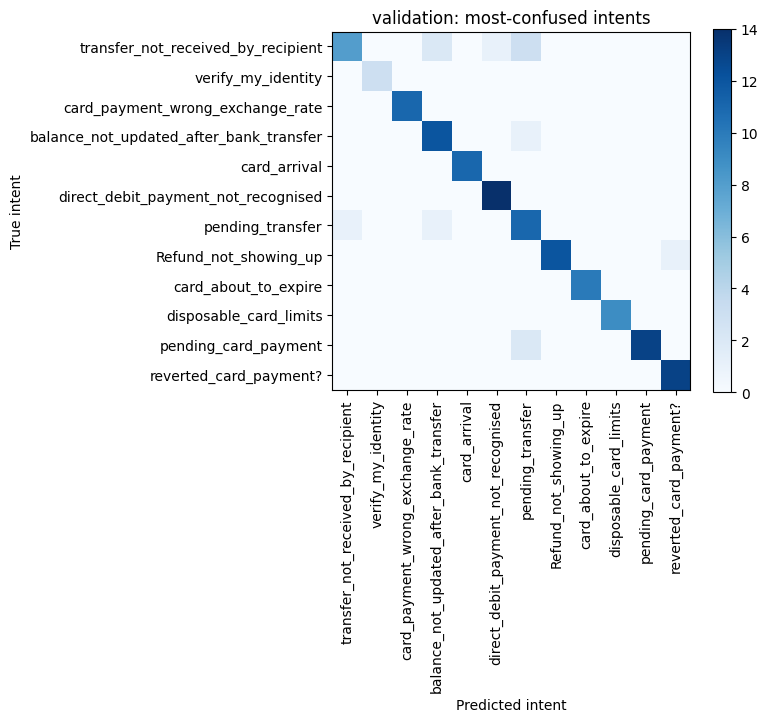

,dataset,method,shot_budget,sampling_mode,seed,sampling_seed,training_seed,backbone,train_size,validation_size,...,test_accuracy,test_macro_f1,train_seconds,prediction_seconds,train_peak_allocated_mib,prediction_peak_allocated_mib,test_prediction_seconds,test_prediction_peak_allocated_mib,gpu,cuda_available
0,banking77,fastfit,None,independent,42,42,42,roberta-base,8996,1000,...,None,None,373.007656,3.529375,6456.09668,562.171387,None,None,NVIDIA GeForce RTX 5060 Laptop GPU,True


Actual training settings: {'model_name_or_path': 'roberta-base', 'label_column_name': 'label', 'text_column_name': 'text', 'num_train_epochs': 1, 'per_device_train_batch_size': 16, 'per_device_eval_batch_size': 16, 'max_text_length': 128, 'num_repeats': 4, 'clf_loss_factor': 0.1, 'optim': 'adafactor', 'seed': 42, 'data_seed': 42, 'fp16': False, 'bf16': False, 'pad_to_max_length': True, 'dataloader_drop_last': False, 'save_strategy': 'no', 'logging_strategy': 'no', 'report_to': [], 'disable_tqdm': True, 'overwrite_output_dir': True, 'effective_query_length': 96, 'learning_rate': 5e-05, 'output_directory_policy': 'temporary directory, removed after training', 'checkpoint_saving': 'disabled', 'file_logging': 'disabled'}
Versions: {'numpy': '2.2.6', 'pandas': '2.3.3', 'torch': '2.11.0+cu128', 'datasets': '2.21.0', 'transformers': '4.44.2', 'fast-fit': '1.2.1', 'scikit-learn': '1.7.2', 'accelerate': '0.34.2', 'matplotlib': '3.10.9', 'huggingface-hub': '0.36.2', 'python': '3.10.22'}
Protocol

In [4]:
runner,training_settings,resources = train_model()
validation_result = evaluate_model(runner,protocol["validation"],"validation")
display_results(validation_result)
test_result = evaluate_model(runner,protocol["test"],"test") if FINAL_TEST else None
if test_result is not None: display_results(test_result)
metrics = dict(dataset=DATASET,method=METHOD,shot_budget=SHOT_BUDGET,sampling_mode=SAMPLING_MODE,
    seed=SEED,sampling_seed=SEED,training_seed=SEED,backbone=BACKBONE,
    train_size=len(train),validation_size=len(protocol["validation"]),test_size=len(protocol["test"]),
    validation_accuracy=validation_result["accuracy"],validation_macro_f1=validation_result["macro_f1"],
    test_accuracy=test_result["accuracy"] if test_result else None,test_macro_f1=test_result["macro_f1"] if test_result else None,
    train_seconds=resources["train_seconds"],prediction_seconds=validation_result["prediction_seconds"],
    train_peak_allocated_mib=resources["train_peak_allocated_mib"],prediction_peak_allocated_mib=validation_result["prediction_peak_allocated_mib"],
    test_prediction_seconds=test_result["prediction_seconds"] if test_result else None,
    test_prediction_peak_allocated_mib=test_result["prediction_peak_allocated_mib"] if test_result else None,
    gpu=GPU_NAME,cuda_available=torch.cuda.is_available(),training_settings=training_settings,
    versions=VERSIONS,protocol_meta=protocol["protocol_meta"])
display(pd.DataFrame([{k:v for k,v in metrics.items() if k not in ["training_settings","versions","protocol_meta"]}]))
print("Actual training settings:",training_settings)
print("Versions:",VERSIONS)
print("Protocol version:", meta["protocol_version"], "| Source IDs:", meta["source_id_order"])
assert np.isfinite(metrics["validation_accuracy"]) and np.isfinite(metrics["validation_macro_f1"]), f"{DATASET}: Validation metrics must be finite"
print("Notebook-only experiment complete; no result files exported. Save this notebook with outputs retained.")


## 历史开发验证 · BANKING77 8-shot

以下数据来自 04 已保存的真实 8-shot 运行，供开发参考。正式 Full Pool 结果在上方运行单元生成。

| Seed | 训练样本 | Validation Accuracy | Macro-F1 | 训练／预测时间 | 训练／预测显存峰值 | 验证错误 |
|---|---:|---:|---:|---:|---:|---:|
| 42 | 616 | 65.50% | 0.645006 | 24.28／2.82 秒 | 4,904／602 MiB | 345 |

设备为 RTX 5060 Laptop GPU。该次仅运行 Validation。